<div style="background-color: steelblue; padding: 10px; border-radius: 5px;">
    <p style="margin: 10;"></p>
    <h1 style="text-align: center; margin: 0; font-weight: bold; color: white;">SWOT OMIP : Seasonality ratio</h1>
    <p style="margin: 10;"></p>
</div>


## 📦**Imports** 

In [1]:
%%time

##################################
#Imports

from datetime import datetime
import s3fs
import xarray as xr
import pyinterp
from widetrax import DataPreprocessing as dp
from widetrax import Spectra as sp
import numpy as np
import json
from watermark import watermark
import time
import platform
from shapely.geometry import shape, box

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
#from widetrax import Spectra as sp
#import plot_psd1Xglobal1 as pp2X
import cum_sp_onl_season_v3 as cs
import importlib
importlib.reload(cs)
import position_function as pf
importlib.reload(pf)

CPU times: user 2.03 s, sys: 485 ms, total: 2.52 s
Wall time: 3.17 s


<module 'position_function' from '/Users/contrema/Documents/Postdoc/SWOTv2/position_function.py'>

## **Map plot functions**

In [2]:
# plot zonal averaged

def plot_fig(ax,imodel,lon_edges,lat_edges,ZW,ZS,valmin,valmax,model,posx,posy):
    ax[posx,posy].add_feature(cfeature.COASTLINE)
    ax[posx,posy].add_feature(cfeature.LAND, facecolor="lightgray")
    mesh = ax[posx,posy].pcolormesh(
        lon_edges,
        lat_edges,
        np.squeeze(ZW[imodel,:,:]/ZS[imodel,:,:]),
        vmin=valmin,
        vmax=valmax,
        cmap='seismic',
        transform=ccrs.PlateCarree()
    )
    ax[posx,posy].set_title(model[imodel])
    ax[posx,posy] = ax[posx,posy].gridlines(draw_labels=True,linewidth=0.2)
    ax[posx,posy].bottom_labels = True
    ax[posx,posy].top_labels = False
    ax[posx,posy].right_labels = False
    ax[posx,posy].left_labels = True
    ax[posx,posy].xlines = False
    ax[posx,posy].ylines = False
    return ax, mesh

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
# plot zonal scatterplot

def plot_spectral_scatter(ax, k_list, specAW_list, specAS_list, specBW_list, specBS_list, labelA, labelB,abc):
    vmin = 0    # minimum color value
    vmax = 282   # maximum color value
    vmin1 = 1e-1    # minimum color value
    vmax1 = 1e1   # maximum color value

    xW_all = np.array(specAW_list)
    yW_all = np.array(specBW_list)
    xS_all = np.array(specAS_list)
    yS_all = np.array(specBS_list)
    k_all = np.array(k_list)


    # remove invalid values (needed for log scale)
    #mask_valid = (xW_all > 0) & (yW_all > 0) & (xS_all > 0) & (yS_all > 0)
    mask_valid1 = (xW_all > 0) & (yW_all > 0) 
    mask_valid2 = (xS_all > 0) & (yS_all > 0)
    # remove invalid values (needed for log scale)
    #mask_scale = (k_all >= 50) & (k_all <= 500)

    #mask = mask_valid# & mask_scale
    xS_all=xS_all[mask_valid2]
    yS_all=yS_all[mask_valid2]
    xW_all=xW_all[mask_valid1]
    yW_all=yW_all[mask_valid1]
    k_all=k_all[mask_valid1]

    # ratio estimation
    x_all=xW_all/xS_all
    y_all=yW_all/yS_all
    slope, intercept, r_value, p_value, std_err = linregress(x_all, y_all)
    sc = ax.scatter(
        x_all,
        y_all,
        c=k_all,
        vmin=vmin,
        vmax=vmax,
        cmap="nipy_spectral",
        s=10,
        alpha=0.7
    )

    # axis scaling
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(abc)

    vmin = min(x_all.min(), y_all.min())
    vmax = max(x_all.max(), y_all.max())

    ax.plot([vmin, vmax], [vmin, vmax], "k--")
    
    ax.set_xlim(vmin1, vmax1)
    ax.set_ylim(vmin1, vmax1)
    ax.text(x=1.2e-1, y=0.7e1, s=f"R2 = {r_value:.3f}", weight="bold")
    ax.grid(True, which="both", ls="--", alpha=0.3)
    ax.set_xlabel(labelA)
    ax.set_ylabel(labelB)

    return sc

## **Load boxes position**

In [4]:
boxesjson="mostly_ocean_boxes_filtered.geojson"
north_boxes, south_boxes=pf.position_boxes_northsouth(boxesjson) # selection of northern and southern hemisphere boxes
selected=pf.position_boxes(boxesjson) # Index boxes for global ocean, and the region


North boxes: 93
South boxes: 189


## **Load Spectrum**

In [ ]:
# -----------------------------
# Analysis for 50-150 km
# -----------------------------
#Define Wavelength range
min_wavelength=50
max_wavelength=150
# models
models=["GLO12V4","GLO36V1","NOC12","NOC025","LLC4320","SWOT"]

# Estimation seasonal ratio of cumulative spectra
R,F=cs.season_spec(models,selected,50,500,north_boxes,south_boxes,"https://minio.dive.edito.eu/",'JFM','JAS',
                  modeload="online",folder="project-meom-ige/OMIP/Global/")

# psdsW winter spectrum list / psdsS summer spectrum list 
psdsW, psdsS,freqJAS=cs.season_cum(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes, "https://minio.dive.edito.eu/",
                                   'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

#  reorganice values of every boxes into a map: ZW (spectrum winter) and ZS (spectrum summer)
ZW,ZS=cs.remap(psdsW,psdsS,models)


/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v3.py:273: RuntimeWarning: divide by zero encountered in divide
  wavelength = 1.0 / freq


In [14]:
# -----------------------------
# Analysis for 150 - 350 km
# -----------------------------
#Define Wavelength range
min_wavelength=150
max_wavelength=350
models=["GLO12V4","GLO36V1","NOC12","NOC025","LLC4320","SWOT"]

# psdsW winter spectrum list / psdsS summer spectrum list 
psdsWL, psdsSL,freqJASL=cs.season_cum(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes,
                                      "https://minio.dive.edito.eu/",'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

#  reorganice values of every boxes into a map: ZW (spectrum winter) and ZS (spectrum summer)
ZWL,ZSL=cs.remap(psdsWL,psdsSL,models)


## **Plotting**
  

In [15]:
# -----------------------------
# Findidng index for latitude to estimate zonal average
# -----------------------------
with open("mostly_ocean_boxes_filtered.geojson") as f:
    data = json.load(f)

latboxes = []
latpos=np.arange(-70,61,10)

for i, feature in enumerate(data["features"]):
    if (i!=14) and (i!=15):
        coords = feature["geometry"]["coordinates"][0]
        first_lat = coords[0][1]  # First coord [lon, lat] → lat is index 1
        latboxes.append(first_lat)

latindex=[]
for i in latpos:
    latindex.append(np.where(latboxes==i))

print(latindex[0])

(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22]),)


/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:219: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:178: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/opt/anaconda3/envs/s3env/lib/python3.14/site-packages/numpy/_core/_methods.py:211: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_40636/1524507207.py:12

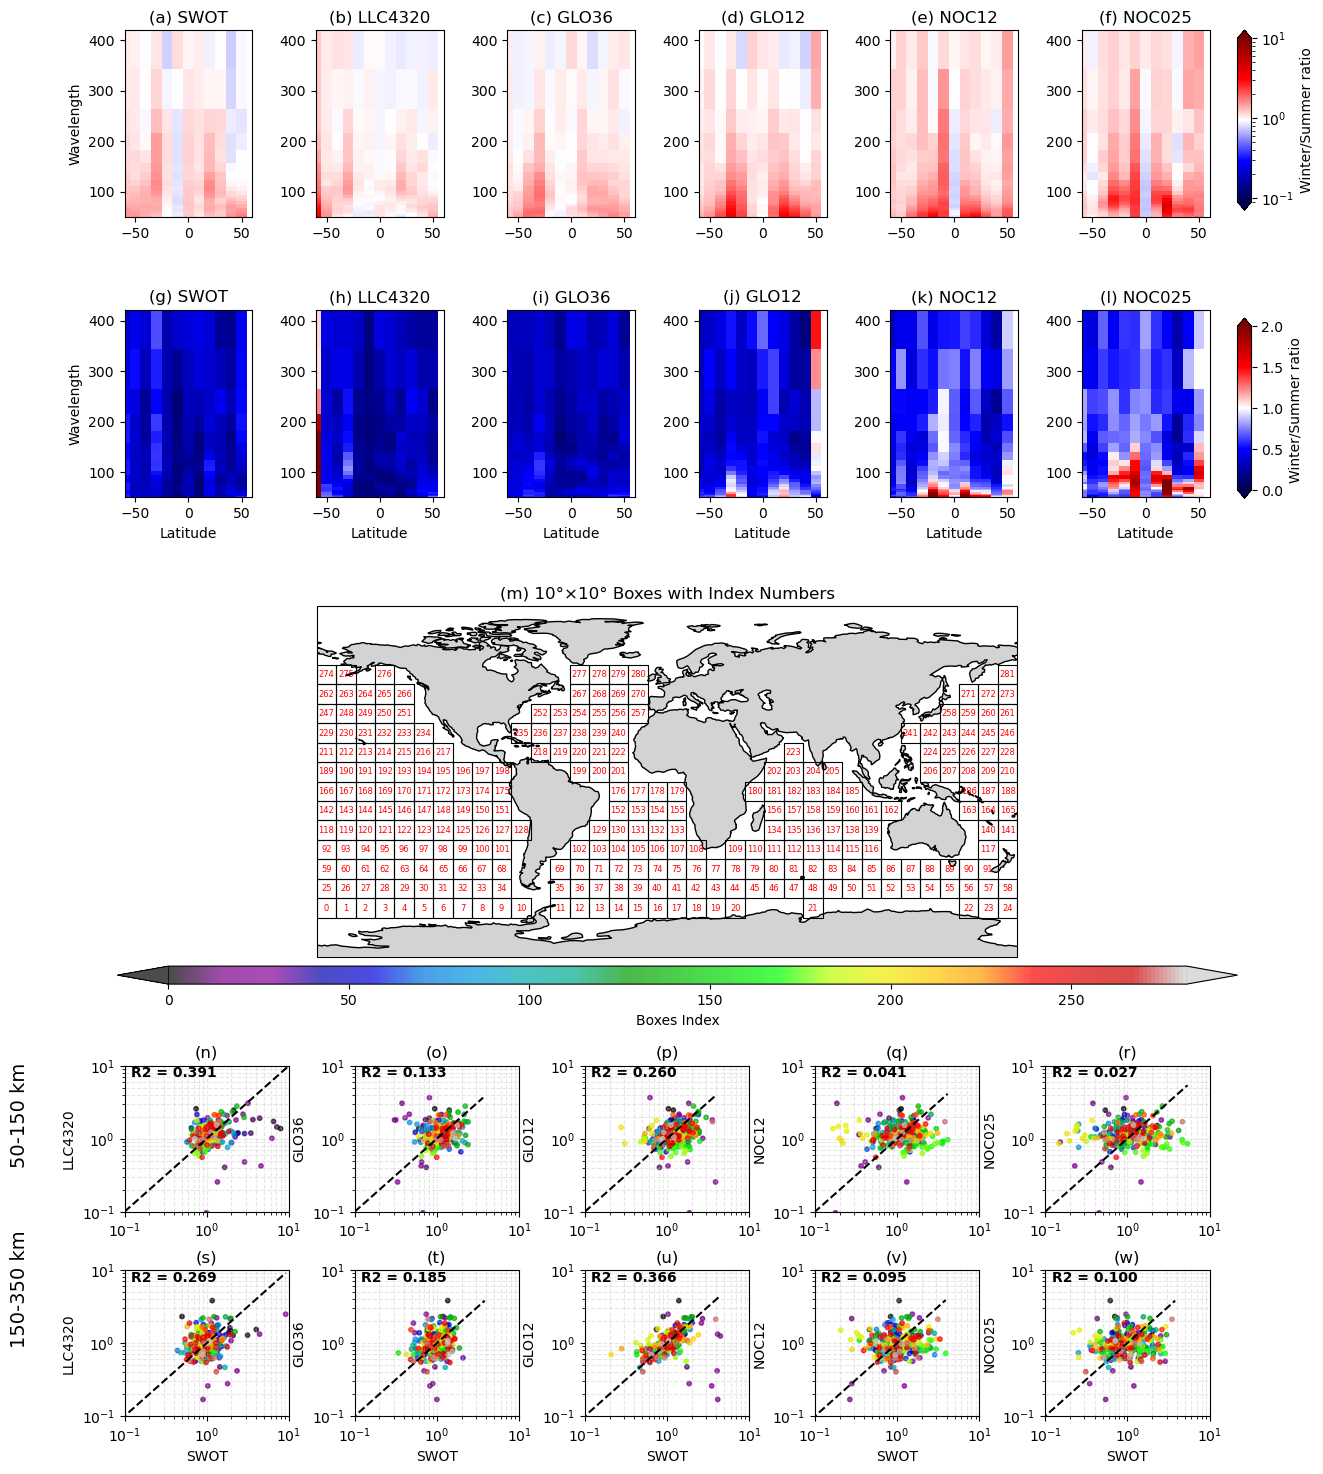

In [16]:
# Plot results

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import matplotlib.colors as mcolors

# -----------------------------
# Definition 
# -----------------------------
model= ["GLO12","GLO36","NOC12","NOC025","LLC4320","SWOT"]
letters=["(n)","(o)","(p)","(q)","(r)","(s)","(t)","(u)","(v)","(w)"]
lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=0
valmax=2

# -----------------------------
# End definition
# -----------------------------
fig = plt.figure(figsize=(14, 18))

# DEFINING AX FOR PLOT
# Outer grid: 3 sections
outer = fig.add_gridspec(
    3, 1,
    height_ratios=[2, 1.5, 1.5],
    hspace=0.28
)


gs_bottom = outer[0].subgridspec(
    2, 6,
    hspace=0.5,
    wspace=0.5
)
ax_new = np.empty((2, 6), dtype=object)

for i in range(2):
    for j in range(6):
        ax_new[i, j] = fig.add_subplot(gs_bottom[i, j])

        
#--------------
# Estimating the zonal averaged of the seasonal ration of cumative spectra.
# Interpolation is apply since not all the SSH spectra boxes has the dimension 
F2 = F[models[0]]#[::20]
Wl=np.squeeze(F2[0]) #à

Fmean=np.zeros((len(Wl),len(latindex),len(models)))
Fstd=np.zeros((len(Wl),len(latindex),len(models)))

kmod=0
for imodel in models:
    RM=R[imodel]
    for i in range(len(latindex)): #len(R)):
        k=0
        pos=latindex[i][0]
        #Fb0 = np.zeros(len(Wl))
        #Fstd = np.zeros(len(Wl))

        F_interp = []

        for ilat in pos:
            F_interp.append(
                np.interp(Wl, np.squeeze(F2[ilat]), np.squeeze(RM[ilat]))
            )
            k += 1
        F_interp = np.array(F_interp)
        Fmean[:, i, kmod] = np.mean(F_interp, axis=0)  # Mean
        Fstd[:, i, kmod] = np.std(F_interp, axis=0)  # Standard deviation (population)

    kmod=kmod+1



mymin=1e1
mymax=1e-1
norm = mcolors.LogNorm(vmin=mymin, vmax=mymax)
imodel=5
pc=ax_new[0,0].pcolormesh(latpos,(1/Wl), np.squeeze(Fmean[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax_new[0,0].set_ylabel("Wavelength")
#ax[2,0].plot( np.abs(RoR)+50,latR,color='k')
#ax[2,0].set_ylabel("Latitude")
ax_new[0,0].set_xlim([-60,60])
ax_new[0,0].set_ylim([50,420])
ax_new[0,0].set_title("(a) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[0,0])

imodel=4
pc=ax_new[0,1].pcolormesh(latpos,(1/Wl), np.squeeze(Fmean[:,:,imodel]), norm=norm,shading='nearest',cmap='seismic')
#ax[0,0].set_xlabel("Wavelength")
#ax[0,0].plot( np.abs(RoR),latR,color='k')
ax_new[0,1].set_xlim([-60,60])
ax_new[0,1].set_ylim([50,420])
ax_new[0,1].set_title("(b) "+model[imodel])
#fig.colorbar(pc,ax=ax_new[0,1])

imodel=1
pc=ax_new[0,2].pcolormesh(latpos,(1/Wl), np.squeeze(Fmean[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax_new[0,2].set_ylim([50,420])
ax_new[0,2].set_xlim([-60,60])
ax_new[0,2].set_title("(c) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[0,2])

imodel=0
pc=ax_new[0,3].pcolormesh(latpos,(1/Wl), np.squeeze(Fmean[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax_new[0,3].set_xlim([-60,60])
ax_new[0,3].set_ylim([50,420])
ax_new[0,3].set_title("(d) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[0,3])

imodel=2
pc=ax_new[0,4].pcolormesh(latpos,(1/Wl), np.squeeze(Fmean[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax_new[0,4].set_xlim([-60,60])
ax_new[0,4].set_ylim([50,420])
ax_new[0,4].set_title("(e) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[0,4])

imodel=3
pc=ax_new[0,5].pcolormesh(latpos,(1/Wl), np.squeeze(Fmean[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax_new[0,5].set_xlim([-60,60])
ax_new[0,5].set_ylim([50,420])
ax_new[0,5].set_title("(f) "+ models[imodel])
cbar_ax = fig.add_axes([0.92, 0.78, .01, 0.1])
cbar = fig.colorbar(pc,cax=cbar_ax, orientation='vertical', fraction=0.02,  extend='both')
cbar.set_label("Winter/Summer ratio")
plt.tight_layout()
#---------
mymin=0
mymax=2
imodel=5
pc=ax_new[1,0].pcolormesh(latpos,(1/Wl), np.squeeze(Fstd[:,:,imodel]),vmin=mymin, vmax=mymax,shading='nearest',cmap='seismic')
ax_new[1,0].set_ylabel("Wavelength")
ax_new[1,0].set_xlabel("Latitude")
ax_new[1,0].set_xlim([-60,60])
ax_new[1,0].set_ylim([50,420])
ax_new[1,0].set_title("(g) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[1,0])

imodel=4
pc=ax_new[1,1].pcolormesh(latpos,(1/Wl), np.squeeze(Fstd[:,:,imodel]), vmin=mymin, vmax=mymax,shading='nearest',cmap='seismic')
ax_new[1,1].set_xlabel("Latitude")
ax_new[1,1].set_xlim([-60,60])
ax_new[1,1].set_ylim([50,420])
ax_new[1,1].set_title("(h) "+model[imodel])
#fig.colorbar(pc,ax=ax_new[1,1])

imodel=1
pc=ax_new[1,2].pcolormesh(latpos,(1/Wl), np.squeeze(Fstd[:,:,imodel]),vmin=mymin, vmax=mymax,shading='nearest',cmap='seismic')
ax_new[1,2].set_xlabel("Latitude")
ax_new[1,2].set_ylim([50,420])
ax_new[1,2].set_xlim([-60,60])
ax_new[1,2].set_title("(i) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[1,2])

imodel=0
pc=ax_new[1,3].pcolormesh(latpos,(1/Wl), np.squeeze(Fstd[:,:,imodel]),vmin=mymin, vmax=mymax,shading='nearest',cmap='seismic')
ax_new[1,3].set_xlabel("Latitude")
ax_new[1,3].set_xlim([-60,60])
ax_new[1,3].set_ylim([50,420])
ax_new[1,3].set_title("(j) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[1,3])

imodel=2
pc=ax_new[1,4].pcolormesh(latpos,(1/Wl), np.squeeze(Fstd[:,:,imodel]),vmin=mymin, vmax=mymax,shading='nearest',cmap='seismic')
ax_new[1,4].set_xlim([-60,60])
ax_new[1,4].set_ylim([50,420])
ax_new[1,4].set_xlabel("Latitude")
ax_new[1,4].set_title("(k) "+ model[imodel])
#fig.colorbar(pc,ax=ax_new[1,4])

imodel=3
pc=ax_new[1,5].pcolormesh(latpos,(1/Wl), np.squeeze(Fstd[:,:,imodel]),vmin=mymin, vmax=mymax,shading='nearest',cmap='seismic')
ax_new[1,5].set_xlabel("Latitude")
ax_new[1,5].set_xlim([-60,60])
ax_new[1,5].set_ylim([50,420])
ax_new[1,5].set_title("(l) "+ model[imodel])
cbar_ax = fig.add_axes([0.92, 0.62, .01, 0.1])
cbar = fig.colorbar(pc,cax=cbar_ax, orientation='vertical', fraction=0.02,  extend='both')
cbar.set_label("Winter/Summer ratio ")
plt.tight_layout()
#________________________________
# HERE START GLOBAL MAP BOXES
ax_big = fig.add_subplot(
    outer[1].subgridspec(1, 1)[0],
    projection=ccrs.PlateCarree()
)

# Large subplot spanning both columns

ax_big.set_global()
ax_big.add_feature(cfeature.LAND, facecolor="lightgray")
ax_big.add_feature(cfeature.COASTLINE)

for i, feature in enumerate(data["features"]):

    poly = shape(feature["geometry"])

    # Draw box
    ax_big.add_geometries(
        [poly],
        ccrs.PlateCarree(),
        edgecolor="black",
        facecolor="none",
        linewidth=0.8
    )

    # Get box center
    lon_min, lat_min, lon_max, lat_max = poly.bounds
    lon_c = 0.5 * (lon_min + lon_max)
    lat_c = 0.5 * (lat_min + lat_max)

    # Add number
    ax_big.text(
        lon_c, lat_c,
        str(i),  # numbering from 1
        transform=ccrs.PlateCarree(),
        ha="center",
        va="center",
        fontsize=6,
        color="red"
    )

ax_big.set_title("(m) 10°×10° Boxes with Index Numbers")
#________________________________
# HERE START SCATTERPLOT
# Remaining 3x2 subplots
gs_middle = outer[2].subgridspec(
    2, 5,
    hspace=0.4,
    wspace=0.4
)

ax = np.empty((2, 5), dtype=object)

for i in range(2):
    for j in range(5):
        ax[i, j] = fig.add_subplot(gs_middle[i, j])

#note that the index 5 represent swot index.
fig.text(0.05, 0.25, '50-150 km', ha='center', fontsize=14,rotation=90)
imodel=4
sc0 = plot_spectral_scatter(ax[0,0],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsS[:,imodel]),
                            np.squeeze(psdsW[:,5]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[0])
imodel=1
sc1 = plot_spectral_scatter(ax[0,1],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsS[:,imodel]),
                            np.squeeze(psdsW[:,5]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[1])
imodel=0
sc2 = plot_spectral_scatter(ax[0,2],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsS[:,imodel]),
                            np.squeeze(psdsW[:,5]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[2])
imodel=2
sc3 = plot_spectral_scatter(ax[0,3],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsS[:,imodel]),
                            np.squeeze(psdsW[:,5]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[3])
imodel=3
sc4 = plot_spectral_scatter(ax[0,4],np.arange(0,282),np.squeeze(psdsW[:,imodel]),np.squeeze(psdsS[:,imodel]),
                            np.squeeze(psdsW[:,5]),np.squeeze(psdsS[:,5])," ", model[imodel],letters[4])


fig.text(0.05, 0.15, '150-350 km', ha='center', fontsize=14, rotation=90)
imodel=4
sc0L = plot_spectral_scatter(ax[1,0],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsSL[:,imodel]),
                            np.squeeze(psdsWL[:,5]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[5])
imodel=1
sc1L = plot_spectral_scatter(ax[1,1],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsSL[:,imodel]),
                            np.squeeze(psdsWL[:,5]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[6])
imodel=0
sc2L = plot_spectral_scatter(ax[1,2],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsSL[:,imodel]),
                            np.squeeze(psdsWL[:,5]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[7])
imodel=2
sc3L = plot_spectral_scatter(ax[1,3],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsSL[:,imodel]),
                            np.squeeze(psdsWL[:,5]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[8])
imodel=3
sc4L = plot_spectral_scatter(ax[1,4],np.arange(0,282),np.squeeze(psdsWL[:,imodel]),np.squeeze(psdsSL[:,imodel]),
                            np.squeeze(psdsWL[:,5]),np.squeeze(psdsSL[:,5]),"SWOT", model[imodel],letters[9])




cbar_ax = fig.add_axes([0.12, 0.35, .8, 0.01])
cbar = fig.colorbar(sc3,cax=cbar_ax, orientation='horizontal', fraction=0.02,  extend='both')
cbar.set_label("Boxes Index")
plt.tight_layout()


#------------------------------



#plt.savefig("FigV2/scatter_global_cumration_modelSWOT2_V3_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False, bbox_inches="tight")
plt.show()


## COMPARISION WITH DE-TIDED

In [18]:
#Define Wavelength range

models=["GLO36V1","GLO36V1NOTIDE","SWOT"]

R,F=cs.season_spec(models,selected,50,500,north_boxes,south_boxes,
                   "https://minio.dive.edito.eu/",'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

min_wavelength=50
max_wavelength=150
# psdsW winter spectrum list / psdsS summer spectrum list 
psdsW, psdsS,freqJAS=cs.season_cum(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes,
                                   "https://minio.dive.edito.eu/",'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

#  reorganice values of every boxes into a map: ZW (spectrum winter) and ZS (spectrum summer)
ZW,ZS=cs.remap(psdsW,psdsS,models)


/Users/contrema/Documents/Postdoc/SWOTv2/cum_sp_onl_season_v3.py:102: RuntimeWarning: divide by zero encountered in divide
  wavelength=1/np.array(freqJFM)


In [19]:
#Define Wavelength range
min_wavelength=150
max_wavelength=350
models=["GLO36V1","GLO36V1NOTIDE","SWOT"]

# psdsW winter spectrum list / psdsS summer spectrum list 
psdsWL, psdsSL,freqJASL=cs.season_cum(models,selected,min_wavelength,max_wavelength,north_boxes,south_boxes,
                                      "https://minio.dive.edito.eu/",'JFM','JAS',modeload="online",folder="project-meom-ige/OMIP/Global/")

#  reorganice values of every boxes into a map: ZW (spectrum winter) and ZS (spectrum summer)
ZWL,ZSL=cs.remap(psdsWL,psdsSL,models)


/var/folders/c9/n_765b212hs2ss0sxlp635dr0000gp/T/ipykernel_40636/3970484950.py:82: RuntimeWarning: invalid value encountered in divide
  Fb1[:,i,kmod]=np.array(Fb0/k)


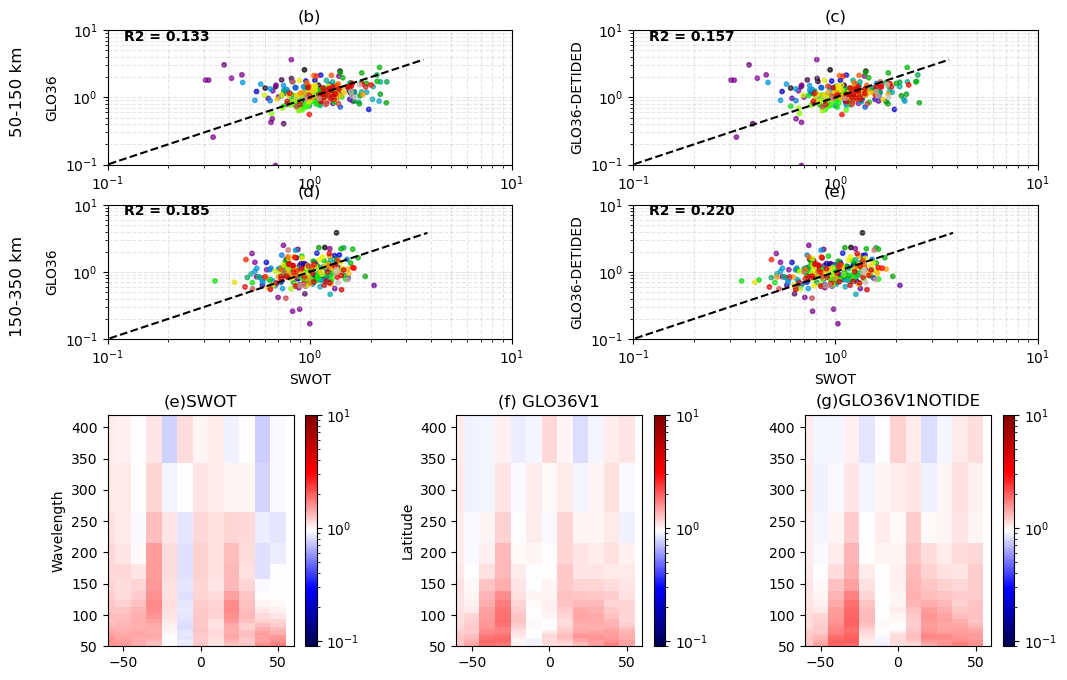

In [20]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import matplotlib.colors as mcolors

model=["GLO36","GLO36-DETIDED","SWOT"]
letters=["(a)","(b)","(c)","(d)","(e)","(f)","(g)","(h)","(i)","(j)","(k)"]
lon_edges = np.arange(-180, 181, 10)
lat_edges = np.arange(-90, 91, 10)

valmin=0
valmax=2

fig = plt.figure(figsize=(12, 8))

# Outer grid: 3 sections
outer = fig.add_gridspec(
    2, 1,
    height_ratios=[2, 1.5],
    hspace=0.28
)

#-------
# Remaining 3x2 subplots
gs_middle = outer[0].subgridspec(
    2, 2,
    hspace=0.3,
    wspace=0.3
)

ax = np.empty((2, 2), dtype=object)

for i in range(2):
    for j in range(2):
        ax[i, j] = fig.add_subplot(gs_middle[i, j])


fig.text(0.05, 0.75, '50-150 km', ha='center', fontsize=12,rotation=90)
sc0 = plot_spectral_scatter(ax[0,0],np.arange(0,282),np.squeeze(psdsW[:,0]),np.squeeze(psdsS[:,0]),
                            np.squeeze(psdsW[:,2]),np.squeeze(psdsS[:,2])," ", model[0],letters[1])
sc1 = plot_spectral_scatter(ax[0,1],np.arange(0,282),np.squeeze(psdsW[:,1]),np.squeeze(psdsS[:,1]),
                            np.squeeze(psdsW[:,2]),np.squeeze(psdsS[:,2])," ", model[1],letters[2])


fig.text(0.05, 0.5, '150-350 km', ha='center', fontsize=12, rotation=90)
sc0L = plot_spectral_scatter(ax[1,0],np.arange(0,282),np.squeeze(psdsWL[:,0]),np.squeeze(psdsSL[:,0]),
                            np.squeeze(psdsWL[:,2]),np.squeeze(psdsSL[:,2]),"SWOT", model[0],letters[3])
sc1L = plot_spectral_scatter(ax[1,1],np.arange(0,282),np.squeeze(psdsWL[:,1]),np.squeeze(psdsSL[:,1]),
                            np.squeeze(psdsWL[:,2]),np.squeeze(psdsSL[:,2]),"SWOT", model[1],letters[4])




#------------------------------
gs_bottom = outer[1].subgridspec(
    1, 3,
    hspace=0.5,
    wspace=0.5
)
ax_new = np.empty((1, 3), dtype=object)

for i in range(1):
    for j in range(3):
        ax_new[i, j] = fig.add_subplot(gs_bottom[i, j])

        
F2 = F[models[0]]#[::20]
Wl=np.squeeze(F2[0]) 

Fb1=np.zeros((len(Wl),len(latindex),len(models)))

kmod=0
for imodel in models:
    RM=R[imodel]
    for i in range(len(latindex)): #len(R)):
        k=0
        pos=latindex[i][0]
        Fb0=np.zeros((len(Wl)))
        for ilat in pos:
            Fb0=Fb0+np.interp(Wl,np.squeeze(F2[ilat]), np.squeeze(RM[ilat]))
            k=k+1
        Fb1[:,i,kmod]=np.array(Fb0/k)
    kmod=kmod+1

model=["GLO36","GLO36 DE-TIDED","SWOT"]


mymin=1e1
mymax=1e-1
norm = mcolors.LogNorm(vmin=mymin, vmax=mymax)
imodel=2
pc=ax_new[0,0].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
ax_new[0,0].set_ylabel("Wavelength")
ax_new[0,0].set_xlim([-60,60])
ax_new[0,0].set_ylim([50,420])
ax_new[0,0].set_title("(e)"+ models[imodel])
fig.colorbar(pc,ax=ax_new[0,0])

imodel=0
pc=ax_new[0,1].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]), norm=norm,shading='nearest',cmap='seismic')
#ax[0,0].set_xlabel("Wavelength")
ax_new[0,1].set_ylabel("Latitude")
ax_new[0,1].set_xlim([-60,60])
ax_new[0,1].set_ylim([50,420])
ax_new[0,1].set_title("(f) "+models[imodel])
fig.colorbar(pc,ax=ax_new[0,1])

imodel=1
pc=ax_new[0,2].pcolormesh(latpos,(1/Wl), np.squeeze(Fb1[:,:,imodel]),norm=norm,shading='nearest',cmap='seismic')
#ax[0,1].set_xlabel("Wavelength")
#ax[0,1].plot( np.abs(RoR)+50,latR,color='k')
#ax[0,1].set_ylabel("Latitude")
#ax[2,2].set_xlabel("Latitude")
ax_new[0,2].set_xlim([-60,60])
ax_new[0,2].set_ylim([50,420])
ax_new[0,2].set_title("(g)"+ models[imodel])
fig.colorbar(pc,ax=ax_new[0,2])



#plt.savefig("FigV2/scatter_global_cumration_modelSWOT2_V2_tidesv2_{}-{}.png".format(min_wavelength,max_wavelength),dpi=300,transparent=False, bbox_inches="tight")
plt.show()



